**Question 1c.i**

- Some time-domain features that are usually used in time series classification are min, max, mean, median, std dev, variance, interquartile range, skewness, kurtosis, autocorrelation, root mean square and crossing rates.

**Question 1c.ii**

In [14]:
import pandas as pd
import glob, os
import numpy as np

cols = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

data = {}

for path in sorted(glob.glob('AReM/*/dataset*.csv')):
    activity = os.path.basename(os.path.dirname(path))
    num = int(os.path.basename(path)[len('dataset'):-4])
    data[(activity, num)] = pd.read_csv(
        path, comment='#', header=None, names=cols, usecols=range(7), sep=r'[,\s]+', engine='python'
    )

print(len(data))




88


In [15]:
rename_map = {
    'min': 'min', 'max': 'max', 'mean': 'mean', 
    '50%': 'median', 'std': 'std', 
    '25%': '1st_quart', '75%': '3rd_quart'
}

rows = []

for (activity, num), df in data.items():
    row_data = {'activity': activity, 'dataset': num}

    for i, col in enumerate(cols[1:], start=1):
        stats = df[col].describe()

        for og, clean in rename_map.items():
            row_data[f"{clean}{i}"] = stats[og]

    rows.append(row_data)

features = pd.DataFrame(rows)

is_bending = features["activity"].str.startswith('bending')
features['is_test'] = (is_bending & (features['dataset'] <= 2)) | (~is_bending & (features['dataset'] <= 3))

features.index = range(1, len(features) + 1)
features.index.name = 'Instance'

features

,activity,dataset,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,...,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,is_test
Instance,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,0.0,...,33.0000,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000,True
2,bending1,2,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,0.0,...,32.0000,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000,True
3,bending1,3,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,...,35.3625,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400,False
4,bending1,4,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,...,30.4575,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000,False
5,bending1,5,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,...,28.4575,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,walking,5,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,0.0,...,14.2500,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050,False
85,walking,6,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,0.0,...,14.2375,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000,False
86,walking,7,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,0.0,...,13.7500,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200,False


**Question 1c.iii**

In [16]:
features_df = features.drop(columns=["activity", 'dataset', 'is_test'])

n_iterations = 1000
confidence = .90
alpha = 1.0 - confidence

lower = (alpha / 2.0) * 100
upper = (1.0 - alpha / 2.0) * 100

bootstrap_results = []
rng = np.random.default_rng(42)


for col in features_df:
    og_data = features_df[col].values
    point_estimate = np.std(og_data, ddof=1)

    boot_stats = []

    for i in range(n_iterations):
        boot_sample = rng.choice(og_data, size=len(og_data), replace=True)

        boot_std = np.std(boot_sample, ddof=1)
        boot_stats.append(boot_std)

    ci_lower = np.percentile(boot_stats, lower)
    ci_upper = np.percentile(boot_stats, upper)

    bootstrap_results.append({
        'Feature': col,
        'Sample_STD': point_estimate,
        'CI_Lower_90%': ci_lower,
        'CI_Upper_90%': ci_upper
    })

bootstrap_summary = pd.DataFrame(bootstrap_results).set_index('Feature')
bootstrap_summary








,Sample_STD,CI_Lower_90%,CI_Upper_90%
Feature,,,
min1,9.569975,8.194325,10.848390
max1,4.394362,3.328131,5.267411
mean1,5.335718,4.666422,5.871471
median1,5.440054,4.800392,5.977818
std1,1.772153,1.562906,1.948855
1st_quart1,6.153590,5.525727,6.665116
3rd_quart1,5.138925,4.341983,5.876490
min2,0.000000,0.000000,0.000000
max2,5.062729,4.587641,5.411003


- min2 and min4 have a std of 0 and a CI of [0, 0] because series 2 and 4 (var_rss12 and var_rss13) hit 0 at some point in every recording, so the min is always 0.

**Question 1c.iv**

- I think the three most important time domain features are mean, max and std dev
- Mean summarizes the overall level which should differ between activities.
- Max will capture the peaks/spikes in the signal and some activities should have higher maxes than others.
- Std captures how much the signal fluctuates and different movements like walking or cycling should fluctuate more than sitting.


**Question 2a(i)**

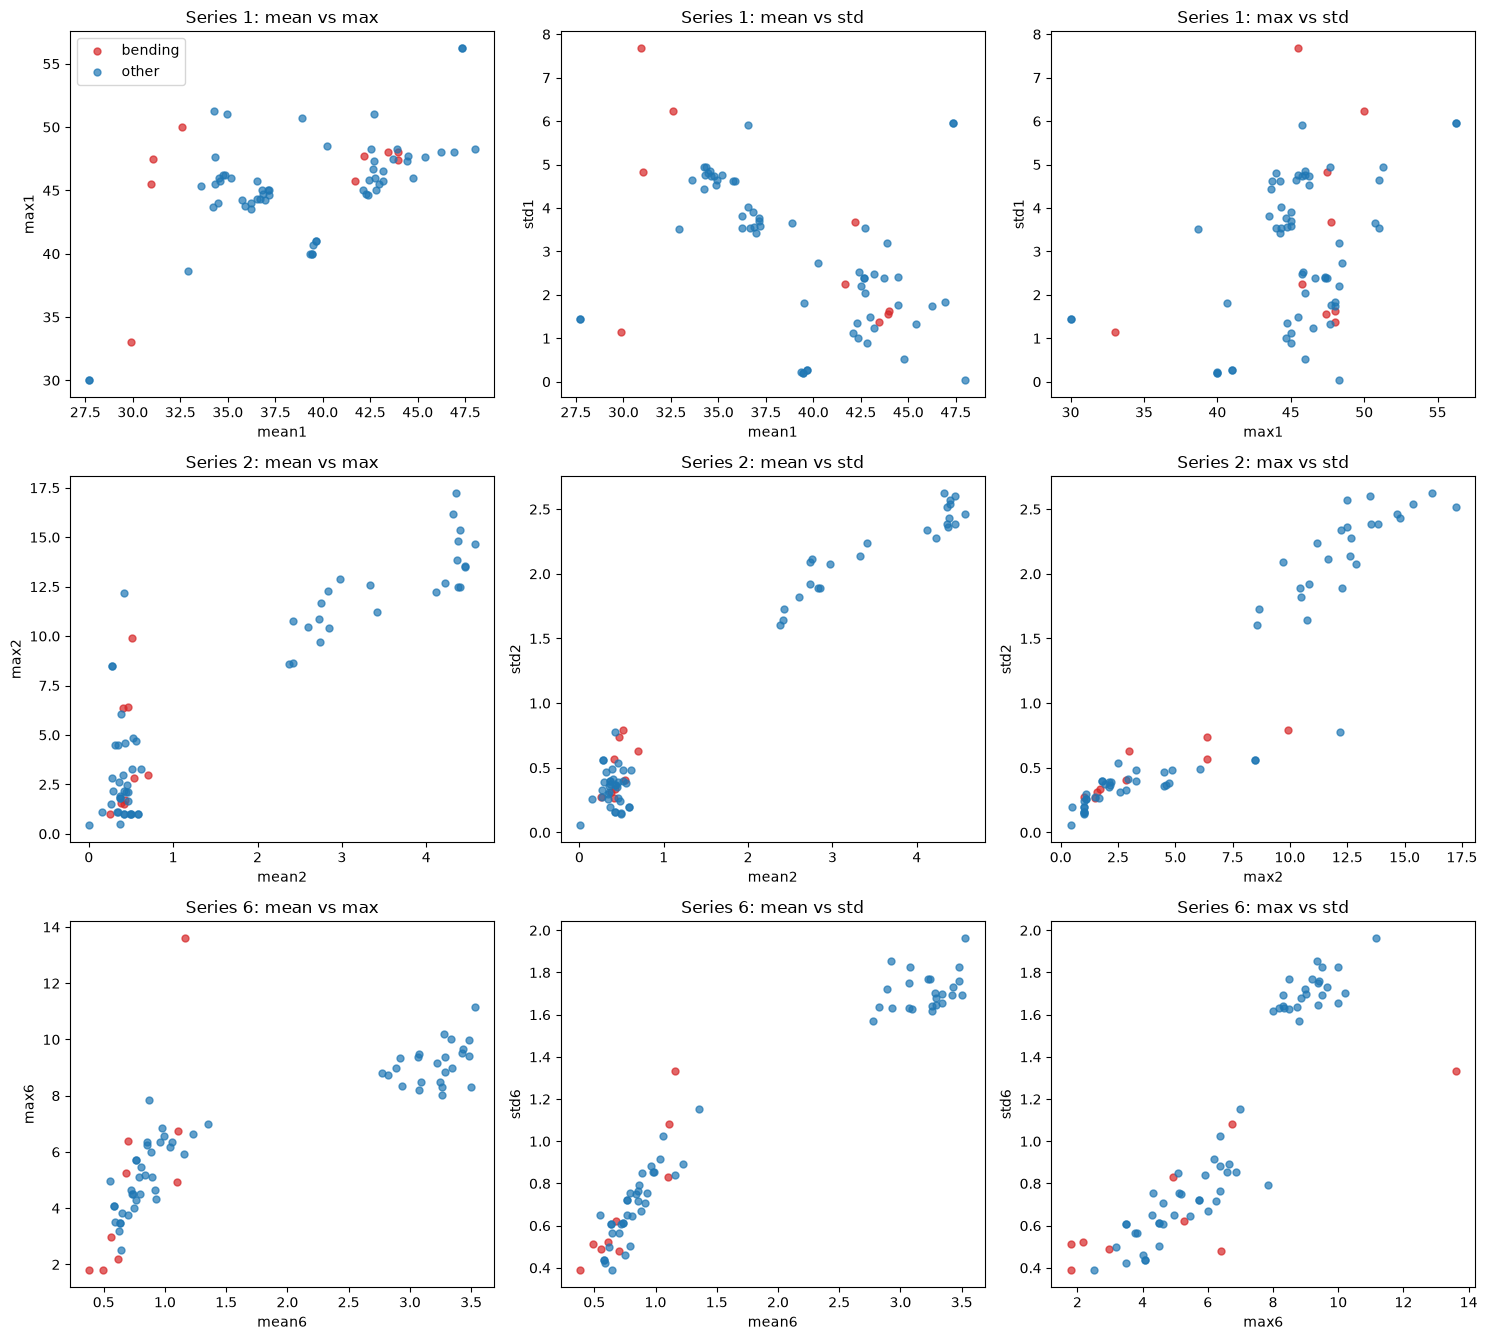

In [17]:
import matplotlib.pyplot as plt
import itertools

train = features[~features["is_test"]].copy()
train["label"] = train["activity"].str.startswith("bending").map({True: "bending", False: "other"})

series_idx = [1, 2, 6]
feat_names = ["mean", "max", "std"]
colors = {"bending": "tab:red", "other": "tab:blue"}

pairs = list(itertools.combinations(feat_names, 2))

fig, axes = plt.subplots(len(series_idx), len(pairs), figsize=(5 * len(pairs), 4.5 * len(series_idx)))

for row, s in enumerate(series_idx):
    for col, (fx, fy) in enumerate(pairs):
        ax = axes[row, col]
        for label, grp in train.groupby("label"):
            ax.scatter(grp[f"{fx}{s}"], grp[f"{fy}{s}"], label=label, alpha=0.7, color=colors[label], s=25)
        ax.set_xlabel(f"{fx}{s}")
        ax.set_ylabel(f"{fy}{s}")
        ax.set_title(f"Series {s}: {fx} vs {fy}")
        if row == 0 and col == 0:
            ax.legend()

plt.tight_layout()
plt.show()

**Question 2a.(ii)**

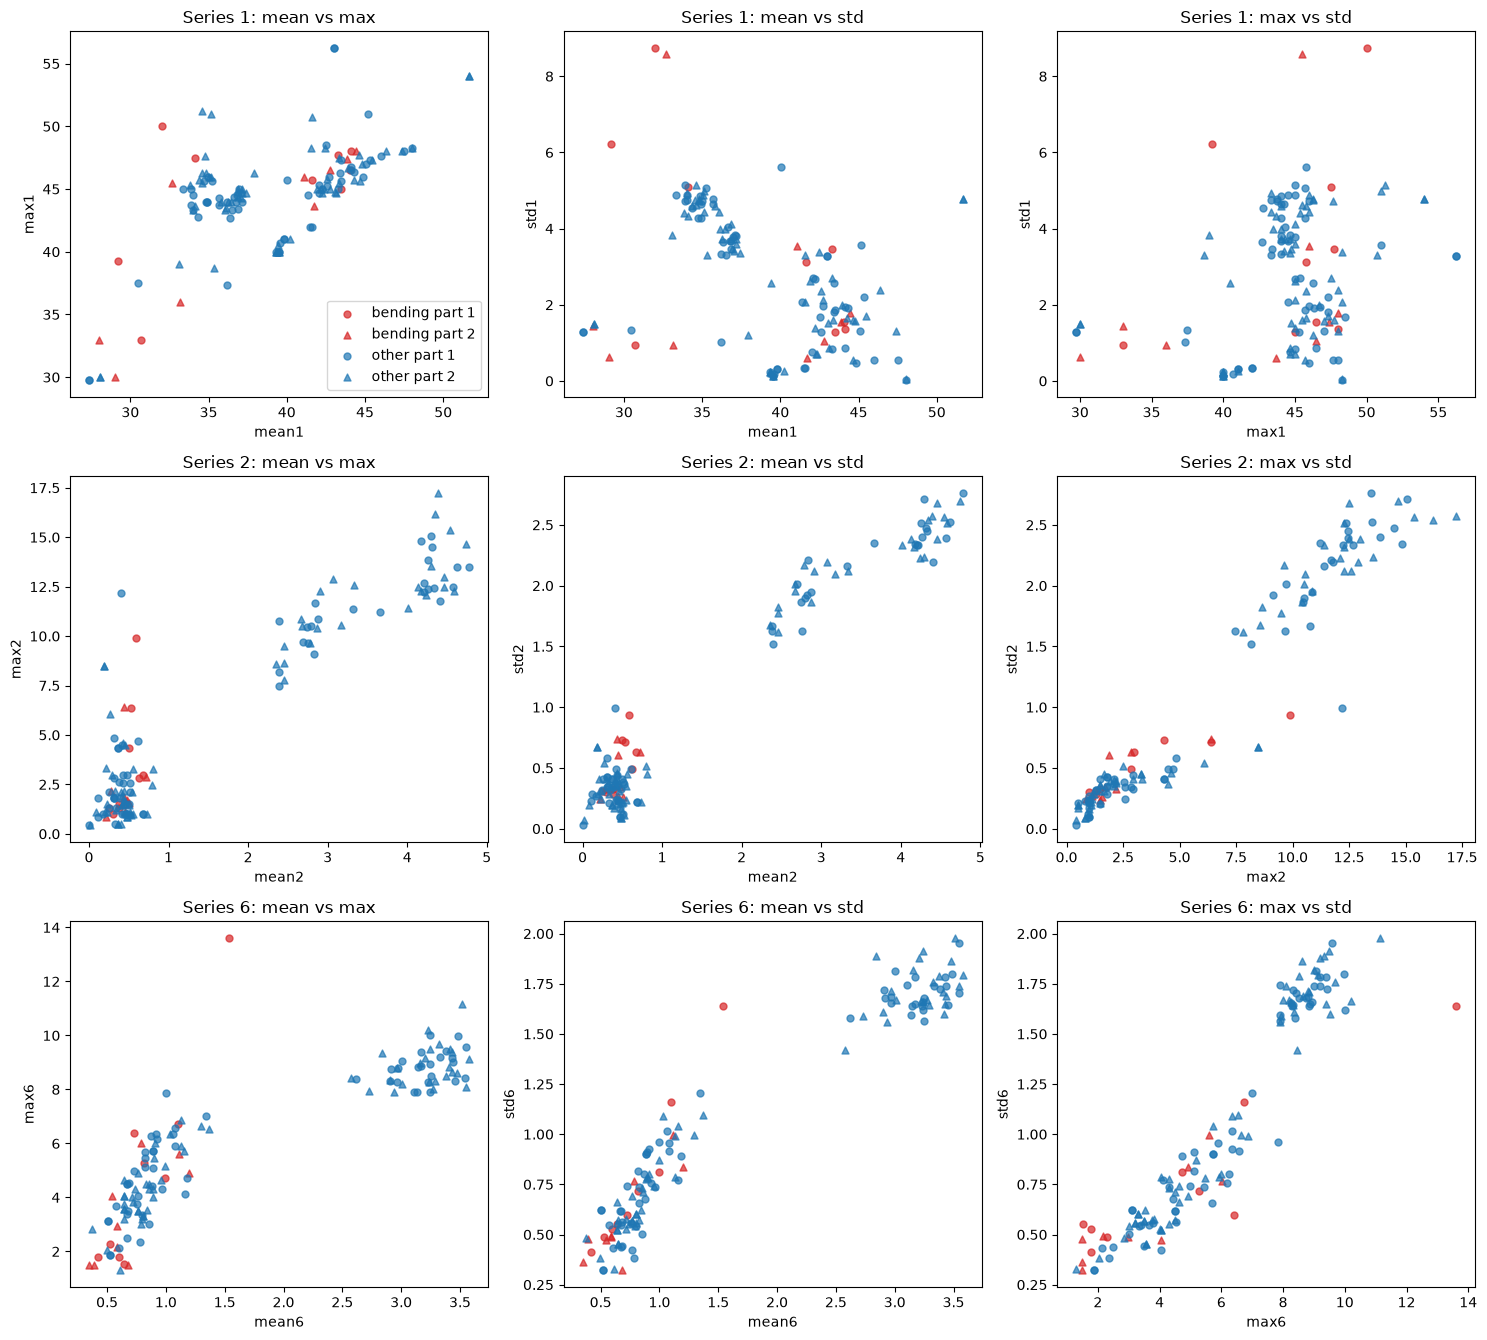

In [18]:
rows = []

for (activity, num), df in data.items():
    row_data = {'activity': activity, 'dataset': num}

    for i, col in enumerate(cols[1:], start=1):
        for j, part in enumerate(np.array_split(df[col], 2), start=1):
            stats = pd.Series(part).describe()

            for og, clean in rename_map.items():
                row_data[f"{clean}{i}_{j}"] = stats[og]

    rows.append(row_data)

features_split = pd.DataFrame(rows)
features_split['is_test'] = features['is_test'].values

train2 = features_split[~features_split["is_test"]].copy()
train2["label"] = train2["activity"].str.startswith("bending").map({True: "bending", False: "other"})

fig, axes = plt.subplots(len(series_idx), len(pairs), figsize=(5 * len(pairs), 4.5 * len(series_idx)))

for row, s in enumerate(series_idx):
    for col, (fx, fy) in enumerate(pairs):
        ax = axes[row, col]
        for label, grp in train2.groupby("label"):
            for j, marker in [(1, "o"), (2, "^")]:
                ax.scatter(grp[f"{fx}{s}_{j}"], grp[f"{fy}{s}_{j}"], label=f"{label} part {j}",
                           alpha=0.7, color=colors[label], marker=marker, s=25)
        ax.set_xlabel(f"{fx}{s}")
        ax.set_ylabel(f"{fy}{s}")
        ax.set_title(f"Series {s}: {fx} vs {fy}")
        if row == 0 and col == 0:
            ax.legend()

plt.tight_layout()
plt.show()

- Not much has changed after splitting the training set into 2. There are twice as many points now since each instance is contributing two points(first half and second half) but even with the added density, there seems to be no visual improvement in separability. The bending class still overlaps with the other activities.

**Question 2a.iii**

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore', module='sklearn')  # hides the convergence warnings from the CV loops

def extract(l):
    rows = []
    for df in data.values():
        row = []
        for col in cols[1:]:
            for part in np.array_split(df[col].values, l):
                q1, med, q3 = np.quantile(part, [.25, .5, .75])
                row += [part.min(), part.max(), part.mean(), med, part.std(ddof=1), q1, q3]
        rows.append(row)
    return np.array(rows)

y = features['activity'].str.startswith('bending').values
test = features['is_test'].values

cv = StratifiedKFold(5, shuffle=True, random_state=42)
results = []

for l in range(1, 21):
    X = extract(l)[~test]
    for p in [1, 2, 3, 5, 8, 10, 15, 20, 30, 40]:
        model = make_pipeline(StandardScaler(),
                              RFE(LogisticRegression(C=1e6, max_iter=1000), n_features_to_select=p, step=0.1))
        score = cross_val_score(model, X, y[~test], cv=cv).mean()
        results.append({'l': l, 'p': p, 'cv_acc': score})

results = pd.DataFrame(results)
results.sort_values('cv_acc', ascending=False).head(10)

,l,p,cv_acc
97,10,20,0.985714
8,1,30,0.985714
24,3,8,0.971429
4,1,8,0.971429
6,1,15,0.971429
7,1,20,0.971429
34,4,8,0.971429
185,19,10,0.971429
67,7,20,0.971429
53,6,5,0.970330


- The best (l, p) combination from the 5 fold stratified CV was l = 10 and p = 20 with an accuracy of .9857. 
- I pruned the features using recursive feature elimination using logistic regression with a very large C so there was almost no L2 penalty.
- The right way is to perform feature selection inside each CV fold using only the training folds, this way the validation fold always stays unseen. The wrong way would be to select features on the whole training set first, since the validation data has been seen already, it will affect the selection and inflate the accuracy.



**Question 2a.(iv)**

                   coef   p_value
const        -24.398074  0.999912
min1_1        -5.644287  0.999992
max1_6        -2.736240  0.999999
std1_6        -7.556927  0.999996
3rd_quart1_6  -3.493871  0.999998
3rd_quart1_7   0.517249  1.000000
std3_3         3.221288  0.999998
1st_quart3_4  -1.489403  0.999999
min3_5         2.860492  0.999997
std3_5        -5.249527  0.999995
std3_8        -3.096942  0.999996
1st_quart4_8   0.685719  0.999999
max5_1         4.922932  0.999997
min5_2        -0.287281  1.000000
mean5_2        0.604816  1.000000
1st_quart5_2  10.755446  0.999995
max5_3         6.370799  0.999997
min5_6         4.938439  0.999998
min5_9         4.050240  0.999997
max6_4        -3.170111  0.999998
max6_8        -3.235016  0.999996
[[60  0]
 [ 0  9]]


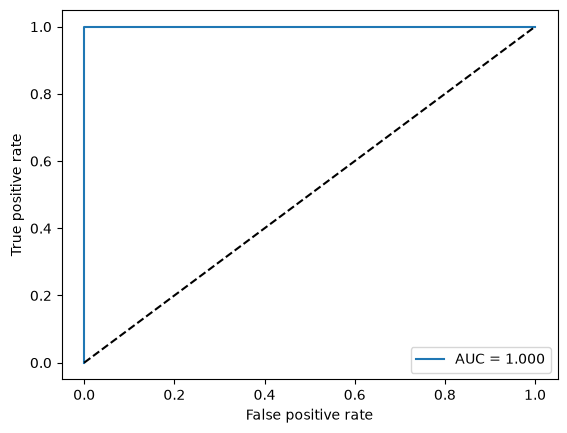

In [20]:
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

l, p = 10, 20
stats = ['min', 'max', 'mean', 'median', 'std', '1st_quart', '3rd_quart']
names = np.array([f"{s}{i}_{k}" for i in range(1, 7) for k in range(1, l + 1) for s in stats])

Xtr, ytr = extract(l)[~test], y[~test].astype(int)

scaler = StandardScaler().fit(Xtr)
Xs = scaler.transform(Xtr)
rfe = RFE(LogisticRegression(C=1e6, max_iter=1000), n_features_to_select=p, step=0.1).fit(Xs, ytr)

# refit on just the selected features with statsmodels so we get p-values
Xsel = sm.add_constant(Xs[:, rfe.support_])
logit = sm.Logit(ytr, Xsel).fit(disp=0, maxiter=200)

row_names = ['const'] + list(names[rfe.support_])
coefs = pd.DataFrame({'coef': logit.params, 'p_value': logit.pvalues}, index=row_names)
print(coefs)

prob = logit.predict(Xsel)
print(confusion_matrix(ytr, prob > 0.5))

fpr, tpr, _ = roc_curve(ytr, prob)
auc = roc_auc_score(ytr, prob)
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC (train)")
plt.legend()
plt.show()

- For the final model, I chose a logistic regression with no regularization using l = 10 and p = 20 features.

- Confusion matrix (train): all 60 other and all 9 bending were classified correctly, so there were no training errors.

- ROC/AUC (train): AUC = 1.000.

- Parameters and p-values: see the coefficient table above. The constant is about -24.4 and the 20 feature coefficients range from about -7.6 (std1_6) to 10.8 (1st_quart5_2). Every p-value is approximately 1.0.

- It seems the training classes are perfectly separable. The perfect training fit is expected with 20 features and only 9 bending instances.

**Question 2a.v**

In [21]:
Xte, yte = extract(l)[test], y[test].astype(int)
Xte_sel = sm.add_constant(scaler.transform(Xte)[:, rfe.support_], has_constant='add')

prob_te = logit.predict(Xte_sel)
pred_te = prob_te > 0.5

print(confusion_matrix(yte, pred_te))
print("test accuracy:", (pred_te == yte).mean())
print("test AUC:", roc_auc_score(yte, prob_te))

[[15  0]
 [ 1  3]]
test accuracy: 0.9473684210526315
test AUC: 1.0


The test set has 19 instances with 4 of them being bending. Each test series was split into l = 10 pieces which is the same as in training. The features also went through the same scaler and the same 20 RFE selected features.

Confusion matrix (test):

| | Predicted other | Predicted bending |
|---|---|---|
| Actual other | 15 | 0 |
| Actual bending | 1 | 3 |

Test accuracy: .947 (18/19 correct). Test AUC: 1.00

- Compared to the cross-validation accuracy which was .986, the test accuracy was slightly lower. However, this difference is a single recording so it isnt very strong evidence of overfitting.

**Question 2a.vi**

Yes the classes seem well separated enough to cause instability. The training AUC was 1.0 with no training errors, so the classes are perfectly separable. statsmodels gives a PerfectSeparationWarning and a ConvergenceWarning when fitting the model in 2a.iv (in the output above), and you can also see it in the coefficients, where every p value is basically 1.

**Question 2a.vii**

- Yes the classes are imbalanced as in the training set there are 60 other vs 9 bending and in the test set there are 15 other vs 4 bending. A model that always predicted other would score pretty high still.

[[14  1]
 [ 1  3]]


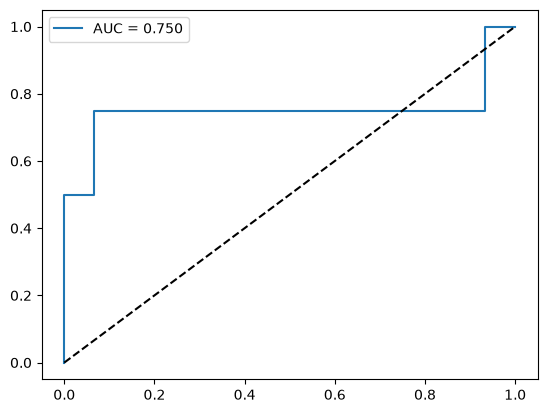

In [22]:
# case-control: keep all the bending (cases) and randomly sample the same number of "other" (controls)
rng = np.random.default_rng(42)
cases = np.where(ytr == 1)[0]
controls = rng.choice(np.where(ytr == 0)[0], size=len(cases), replace=False)
idx = np.concatenate([cases, controls])

Xcc = scaler.transform(Xtr)[idx][:, rfe.support_]
cc = sm.Logit(ytr[idx], sm.add_constant(Xcc)).fit(disp=0, maxiter=200)

# fix the intercept: add log(pi / (1 - pi)) using the real bending rate
# (the sample is 50/50 so the log(pi_tilde / (1 - pi_tilde)) part is just 0)
params = cc.params.copy()
params[0] += np.log(len(cases) / (len(ytr) - len(cases)))

Xte_sel = sm.add_constant(scaler.transform(Xte)[:, rfe.support_], has_constant='add')
z = Xte_sel @ params
prob_cc = 1 / (1 + np.exp(-z))

print(confusion_matrix(yte, prob_cc > 0.5))
fpr, tpr, _ = roc_curve(yte, prob_cc)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(yte, prob_cc):.3f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC (test, case-control)")
plt.legend()
plt.show()

- After performing case control sampling I got these results:

- Confusion matrix (test):

| | Predicted other | Predicted bending |
|---|---|---|
| Actual other | 14 | 1 |
| Actual bending | 1 | 3 |

- ROC/AUC (test): AUC = 0.750.

- The accuracy dropped from .947 to .895 and the AUC dropped from 1.000 to .750 so case control sampling did not help here. 


**Question 2bi**

In [23]:
results = []

for l in range(1, 21):
    X = extract(l)[~test]
    for C in np.logspace(-2, 2, 9):
        model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear', C=C))
        results.append({'l': l, 'C': C, 'cv_acc': cross_val_score(model, X, y[~test], cv=cv).mean()})

results = pd.DataFrame(results)
# lots of ties, so sort by smallest l and then smallest C (stronger penalty) after accuracy
results = results.sort_values(['cv_acc', 'l', 'C'], ascending=[False, True, True])
results.head(10)

,l,C,cv_acc
179,20,100.000000,0.971429
106,12,31.622777,0.971429
176,20,3.162278,0.971429
15,2,10.000000,0.971429
104,12,3.162278,0.971429
178,20,31.622777,0.971429
105,12,10.000000,0.971429
103,12,1.000000,0.971429
5,1,3.162278,0.971429
89,10,100.000000,0.971429


In [24]:
best = results.iloc[0]
lb, Cb = int(best['l']), best['C']

model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear', C=Cb))
model.fit(extract(lb)[~test], y[~test])
Xte_b = extract(lb)[test]

print(confusion_matrix(y[test], model.predict(Xte_b)))
print("test accuracy:", model.score(Xte_b, y[test]))
print("test AUC:", roc_auc_score(y[test], model.predict_proba(Xte_b)[:, 1]))
print("nonzero coefficients:", (model[-1].coef_ != 0).sum())

[[15  0]
 [ 1  3]]
test accuracy: 0.9473684210526315
test AUC: 0.9666666666666667
nonzero coefficients: 52


- I cross validated over l from 1 to 20 and 9 values of C from 0.01 to 100 (log spaced). The scaler is inside the pipeline so it only gets fit on the training folds.
- A lot of combinations tied at a CV accuracy of .971, so I broke ties by picking the smallest l and then the smallest C (more penalty). That gave l = 1 and C = 3.16.
- On the test set it got all 19 right (accuracy 1.0, AUC 1.0), and the L1 penalty only kept 8 of the 42 features.

**Question 2bii**

- The L1 model had a CV accuracy of .971 which is slightly lower than the .986 from the p-value/RFE model, but it did better on the test set (1.0 vs .947 accuracy). Test AUC was 1.0 for both.
- These differences are only one or two recordings so I would say they perform about the same. The L1 model is a lot simpler though, it only uses l = 1 and 8 features compared to l = 10 and 20 features for the RFE model.
- L1 is also way easier to implement. It's just one LogisticRegression with penalty='l1', while the other way needs RFE, then a refit in statsmodels to get the p values. I would use L1 for this problem.

**Question 2c.i**

In [25]:
ym = features['activity'].values

results = []

for l in [1, 2, 3, 5, 8, 10]:
    X = extract(l)[~test]
    for C in [0.1, 1, 10]:
        model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='saga', C=C, max_iter=1000, tol=1e-3))
        results.append({'l': l, 'C': C, 'cv_acc': cross_val_score(model, X, ym[~test], cv=cv).mean()})

results = pd.DataFrame(results)
results = results.sort_values(['cv_acc', 'l', 'C'], ascending=[False, True, True])
results.head(10)

,l,C,cv_acc
4,2,1.0,0.914286
5,2,10.0,0.914286
1,1,1.0,0.884615
2,1,10.0,0.870330
11,5,10.0,0.856044
7,3,1.0,0.827473
8,3,10.0,0.827473
14,8,10.0,0.827473
17,10,10.0,0.812088
13,8,1.0,0.812088


In [26]:
best = results.iloc[0]
lm, Cm = int(best['l']), best['C']

model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='saga', C=Cm, max_iter=1000, tol=1e-3))
model.fit(extract(lm)[~test], ym[~test])
Xte_m = extract(lm)[test]

pred = model.predict(Xte_m)
print(pd.DataFrame(confusion_matrix(ym[test], pred, labels=model.classes_), index=model.classes_, columns=model.classes_))
print("test error:", 1 - model.score(Xte_m, ym[test]))
print("macro one-vs-rest AUC:", roc_auc_score(ym[test], model.predict_proba(Xte_m), multi_class='ovr', labels=model.classes_))

          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         1        0      0        1         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          0         0        0      0        1         2        0
standing         0         0        0      0        0         3        0
walking          0         0        0      0        0         0        3
test error: 0.1578947368421053
macro one-vs-rest AUC: 0.9677871148459384


In [ ]:
from sklearn.preprocessing import label_binarize

# one vs rest ROC: each activity is the positive class and everything else is negative
y_bin = label_binarize(ym[test], classes=model.classes_)
probs = model.predict_proba(Xte_m)

plt.figure(figsize=(7, 6))
for k, activity in enumerate(model.classes_):
    fpr, tpr, _ = roc_curve(y_bin[:, k], probs[:, k])
    plt.plot(fpr, tpr, label=f"{activity} (AUC = {roc_auc_score(y_bin[:, k], probs[:, k]):.2f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("One vs rest ROC (test)")
plt.legend()
plt.show()

- I ran a L1 penalized multinomial logistic regression on all 7 activities with stratified 5 fold CV over l in [1,2,3,5,8,10] and C in [.1,1,10]. I used a smaller grid than in 2b because the saga solver was really slow with a lot of features (large l), so trying all 20 values of l would have taken too long.
- Best: l = 2, C = 1.0 with CV accuracy of 0.914
- Test error: 0.158 (16/19 correct)
- For multiclass, the confusion matrix is just 7x7 with the actual class in the rows and the predicted class in the columns, so the diagonal is the correct predictions. Most of the mistakes were sitting being predicted as standing.
- For ROC, I did one vs rest where each class is treated as positive and all the others as negative, which gives one curve per class (plotted above). Averaging those AUCs gives the macro AUC = .971

**Question 2c.ii**

In [27]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

gnb_results = []

for l in range(1, 21):
    X = extract(l)[~test]
    model = make_pipeline(StandardScaler(), GaussianNB())
    score = cross_val_score(model, X, ym[~test], cv=cv).mean()
    gnb_results.append({'l': l, 'cv_acc': score})

gnb_results = pd.DataFrame(gnb_results)
gnb_results.sort_values('cv_acc', ascending=False).head(10)

,l,cv_acc
0,1,0.857143
1,2,0.827473
3,4,0.725275
2,3,0.681319
9,10,0.681319
7,8,0.681319
6,7,0.680220
10,11,0.652747
5,6,0.652747
4,5,0.652747


In [28]:
best_g = gnb_results.sort_values('cv_acc', ascending=False).iloc[0]
lg = int(best_g['l'])

gnb = make_pipeline(StandardScaler(), GaussianNB())
gnb.fit(extract(lg)[~test], ym[~test])
Xte_g = extract(lg)[test]

pred_g = gnb.predict(Xte_g)
print(pd.DataFrame(confusion_matrix(ym[test], pred_g, labels=gnb.classes_), index=gnb.classes_, columns=gnb.classes_))
print("test error:", 1 - gnb.score(Xte_g, ym[test]))
print("macro one-vs-rest AUC:", roc_auc_score(ym[test], gnb.predict_proba(Xte_g), multi_class='ovr', labels=gnb.classes_))

          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         2        0      0        0         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      2        1         0        0
sitting          0         0        0      0        3         0        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3
test error: 0.10526315789473684
macro one-vs-rest AUC: 0.9642857142857143


In [29]:
mnb_results = []

for l in range(1, 21):
    X = extract(l)[~test]
    model = make_pipeline(MinMaxScaler(), MultinomialNB())
    score = cross_val_score(model, X, ym[~test], cv=cv).mean()
    mnb_results.append({'l': l, 'cv_acc': score})

mnb_results = pd.DataFrame(mnb_results)
mnb_results.sort_values('cv_acc', ascending=False).head(10)

,l,cv_acc
1,2,0.751648
0,1,0.723077
2,3,0.723077
3,4,0.723077
7,8,0.723077
4,5,0.723077
5,6,0.694505
6,7,0.694505
8,9,0.694505
17,18,0.680220


In [30]:
best_m = mnb_results.sort_values('cv_acc', ascending=False).iloc[0]
lm_nb = int(best_m['l'])

mnb = make_pipeline(MinMaxScaler(), MultinomialNB())
mnb.fit(extract(lm_nb)[~test], ym[~test])
Xte_n = extract(lm_nb)[test]

pred_n = mnb.predict(Xte_n)
print(pd.DataFrame(confusion_matrix(ym[test], pred_n, labels=mnb.classes_), index=mnb.classes_, columns=mnb.classes_))
print("test error:", 1 - mnb.score(Xte_n, ym[test]))
print("macro one-vs-rest AUC:", roc_auc_score(ym[test], mnb.predict_proba(Xte_n), multi_class='ovr', labels=mnb.classes_))

          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         1        0      0        1         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        1      2        0         0        0
sitting          0         0        0      0        2         1        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3
test error: 0.21052631578947367
macro one-vs-rest AUC: 0.9672619047619048


- Gaussian NB: best l = 1, CV accuracy of 0.857, test error 0.105 and macro AUC 0.964
- Multinomial NB: best l = 2, CV accuracy .752, test error 0.211, macro AUC 0.967

- Gaussian is better on both CV and test. Since the features are all continuous stats and not counts, the multinomial assumption was a poor fit. 

**Question 2(c)iii**
- L1 multinomial regression had the best CV accuracy (.914 vs .857 for Gaussian NB and .752 for Multinomial NB), but Gaussian NB had the lowest test error (.105 vs .158 for L1). The macro AUCs were all close (.971, .964, .967).
- Multinomial NB was the weakest overall, which makes sense since the features are continuous stats and not counts.
- So it's close between L1 and Gaussian NB. The test set only has 19 recordings so one or two mistakes changes the test error a lot, which is why I would trust the CV accuracy more and go with L1 multinomial regression. Gaussian NB is still a good option since it's much faster and doesn't have a C to tune.

**Question ISLR 4.8.3**

Since the Bayes classifier picks the class $k$ with the largest $\pi_k f_k(x)$, we can take logs and drop the terms that are the same for every class, then pick the class with the largest score:

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{x\mu_k}{\sigma_k^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log \pi_k - \log \sigma_k$$

This has an $x^2$ term, an $x$ term and a constant, so it's a quadratic function of $x$.

It's not linear because if we compare classes $j$ and $k$ we set $\delta_j(x) = \delta_k(x)$. The $x^2$ parts of the two scores are $-\frac{x^2}{2\sigma_j^2}$ and $-\frac{x^2}{2\sigma_k^2}$.
- If $\sigma_j = \sigma_k$ (the LDA case in Section 4.4.1) these are the same and cancel, leaving a linear equation in $x$.
- If $\sigma_j \neq \sigma_k$ they don't cancel, so the boundary equation has an $x^2$ term. That makes it a quadratic equation, which can have two solutions.

For example, take two classes with equal priors, $\mu_1 = \mu_2 = 0$, $\sigma_1 = 1$ and $\sigma_2 = 2$. The scores become:
- Class 1: $-0.5x^2$
- Class 2: $-0.125x^2 - 0.693$

Setting them equal gives $-0.375x^2 + 0.693 = 0$, so $x \approx \pm 1.36$. There are two boundary points instead of one, so the boundary isn't a single linear cutoff. Class 1 wins between -1.36 and 1.36 and class 2 wins outside that range.

**Question ISLR 4.8.7**

Using Bayes' theorem, the $\frac{1}{\sqrt{2\pi\sigma^2}}$ part cancels since both classes have the same $\sigma^2 = 36$.

$$P(\text{Yes} \mid x=4) = \frac{0.8\,e^{-(4-10)^2/72}}{0.8\,e^{-(4-10)^2/72} + 0.2\,e^{-(4-0)^2/72}}$$

$$= \frac{0.8\,e^{-0.5}}{0.8\,e^{-0.5} + 0.2\,e^{-0.2222}} = \frac{0.4852}{0.4852 + 0.1601} \approx 0.752$$

So there's about a 75.2% chance that the company issues a dividend.